## Que. 2

### Refer the “Engine.csv” and observe the dataset and decide type of Regression.
Datasets provide fuel consumption ratings and estimated carbon dioxide emissions for new light-duty vehicles for retail sale in Canada.
Predict the Co2emission for with given fuel consumption ratings CYLINDERS, ENGINESIZE, FUELCONSUMPTION_COMB.
Calculate different errors to evaluate the model.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv("Engine.csv")
df.head()

,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_COMB,CO2EMISSIONS
0,2.0,4,8.5,196
1,2.4,4,9.6,221
2,1.5,4,5.9,136
3,3.5,6,11.1,255
4,3.5,6,10.6,244


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067 entries, 0 to 1066
Data columns (total 4 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ENGINESIZE            1067 non-null   float64
 1   CYLINDERS             1067 non-null   int64  
 2   FUELCONSUMPTION_COMB  1067 non-null   float64
 3   CO2EMISSIONS          1067 non-null   int64  
dtypes: float64(2), int64(2)
memory usage: 33.5 KB


In [5]:
df.describe()

,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_COMB,CO2EMISSIONS
count,1067.000000,1067.000000,1067.000000,1067.000000
mean,3.346298,5.794752,11.580881,256.228679
std,1.415895,1.797447,3.485595,63.372304
min,1.000000,3.000000,4.700000,108.000000
25%,2.000000,4.000000,9.000000,207.000000
50%,3.400000,6.000000,10.900000,251.000000
75%,4.300000,8.000000,13.350000,294.000000
max,8.400000,12.000000,25.800000,488.000000


In [6]:
df.corr()

,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_COMB,CO2EMISSIONS
ENGINESIZE,1.000000,0.934011,0.819482,0.874154
CYLINDERS,0.934011,1.000000,0.776788,0.849685
FUELCONSUMPTION_COMB,0.819482,0.776788,1.000000,0.892129
CO2EMISSIONS,0.874154,0.849685,0.892129,1.000000


<Axes: >

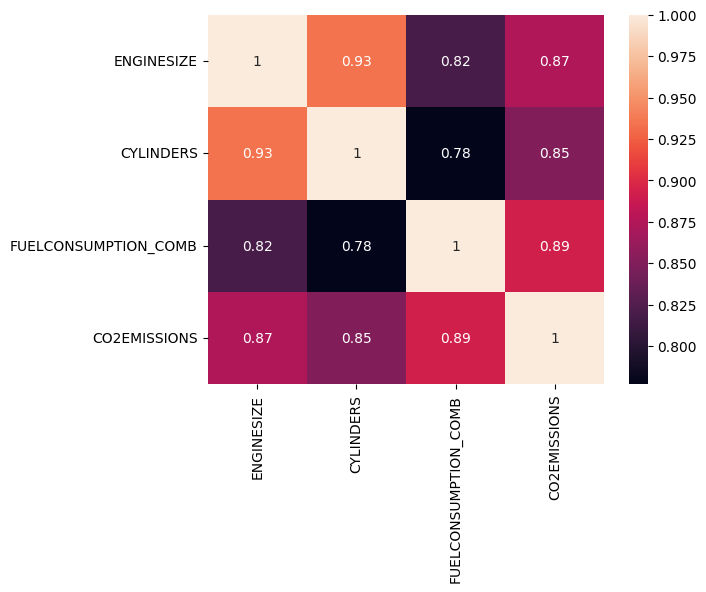

In [9]:
sns.heatmap(df.corr(),annot=True)

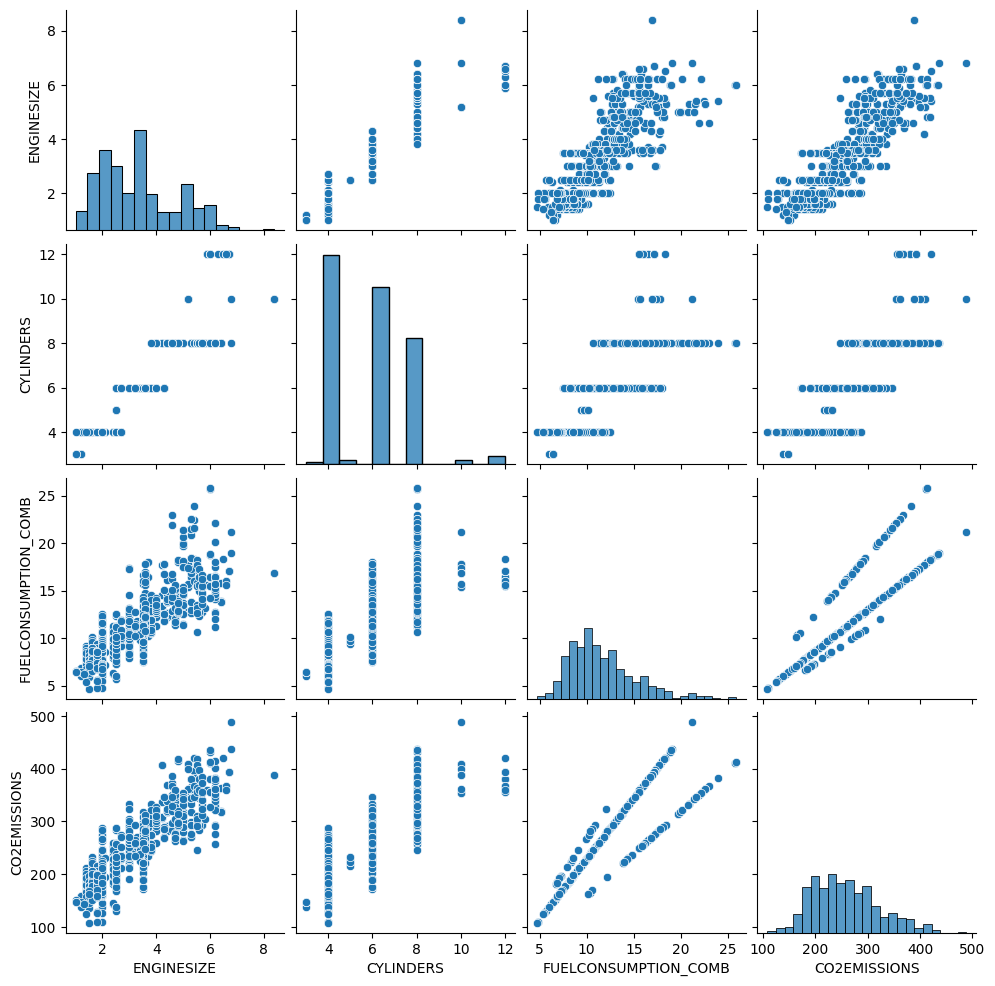

In [10]:
sns.pairplot(df)

In [12]:
X=df.drop('CO2EMISSIONS',axis=1)
y=df['CO2EMISSIONS']

In [13]:
X.columns

Index(['ENGINESIZE', 'CYLINDERS', 'FUELCONSUMPTION_COMB'], dtype='object')

In [14]:
from sklearn.model_selection import train_test_split
X_tarin,X_test,y_train,y_test=train_test_split(X,y,train_size=0.7,random_state=42)

In [15]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(X_tarin,y_train)

LinearRegression()

In [16]:
y_pred=model.predict(X_test)

In [17]:
from sklearn.metrics import mean_absolute_error
mae=mean_absolute_error(y_test,y_pred)
print(f"mean absolute error={mae:.2f}")

mean absolute error=16.54


In [18]:
from sklearn.metrics import mean_absolute_percentage_error
mape=mean_absolute_percentage_error(y_test,y_pred)
print(f"mean absolute percentage error={mape:.2f}")

mean absolute percentage error=0.07


In [19]:
from sklearn.metrics import mean_squared_error
mse=mean_squared_error(y_test,y_pred)
print(f"ean_squared_erro={mae:.2f}")

ean_squared_erro=16.54


In [20]:
from sklearn.metrics import r2_score
r2=r2_score(y_test,y_pred)
print(f"r2={r2:.2f}")

r2=0.88


In [21]:
n=y_test.size
p=2
adjusted_r2=1-((1-r2)*((n-1)/(n-p-1)))
print(f"adjested r2={adjusted_r2:.2f}")

adjested r2=0.87


In [23]:
import pickle
with open("Engine_model.pkl","wb") as file:
    pickle.dump(model,file)